In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [ ]:
def get_rc_and_err(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [4]:
def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [5]:
import math
def weighted_avg_and_std(values, weights):
    """
    Return the weighted average and standard deviation.

    values, weights -- Numpy ndarrays with the same shape.
    """
    average = np.average(values, weights=weights)
    # Fast and numerically precise:
    variance = np.average((values-average)**2, weights=weights)
    return (average, math.sqrt(variance))

In [23]:
observables = ['evid','xsec','pt','n','parton','nch','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m','nparents1','nparents2']

In [24]:
files = ['/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_50pthat1000_rc_truth.txt']

In [25]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [ ]:
df = df.query('pt>20')
df.eval('b_ch = q1*q2', inplace=True)

In [8]:
print('number of jets with q1 == -1:', df[df.q1==-1].shape[0])
print('number of jets with q1 == +1:', df[df.q1==1].shape[0])

number of jets with q1 == -1: 590165
number of jets with q1 == +1: 847841


In [ ]:
df = df.query('abs(parent1)>15 and abs(parent2)>15 and abs(pid1)>15 and abs(pid2)>15')

In [18]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [ ]:
nodecay_rc_array = []
nodecay_rc_err_array = []
for i in range(0, len(df_array)):
    nodecay_rc_array.append(get_rc_and_err(df_array[i], 'b_ch')[0])
    nodecay_rc_err_array.append(get_rc_and_err(df_array[i], 'b_ch')[1])

In [13]:
df_array = []
for i in range(1, 6):
    df_array.append(df[(df.n>2*i) & (df.n<2*(i+1))])

In [ ]:
nodecay_rc_array = []
nodecay_rc_err_array = []
for i in range(0, len(df_array)):
    nodecay_rc_array.append(get_rc_and_err(df_array[i], 'b_ch')[0])
    nodecay_rc_err_array.append(get_rc_and_err(df_array[i], 'b_ch')[1])

In [28]:
y_nodecay, yerr_nodecay = calc_hist(df['n'], bins=np.arange(2,16), weights=df['w'], density=True)[:2]

In [13]:
print(weighted_avg_and_std(df['n'], weights=df['w']))

(5.623654762183312, 1.7258544872494033)


In [41]:
files = ['/gpfs/gibbs/project/havener/ys668/rc/pythia_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_50pthat1000_rc_truth.txt']

In [42]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [ ]:
df = df.query('pt>20')
df.eval('b_ch = q1*q2', inplace=True)

In [23]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [ ]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(get_rc_and_err(df_array[i], 'b_ch')[0])
    rc_err_array.append(get_rc_and_err(df_array[i], 'b_ch')[1])

In [20]:
df_array = []
for i in range(1, 6):
    df_array.append(df[(df.n>2*i) & (df.n<2*(i+1))])

In [ ]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(get_rc_and_err(df_array[i], 'b_ch')[0])
    rc_err_array.append(get_rc_and_err(df_array[i], 'b_ch')[1])

In [44]:
y, yerr = calc_hist(df['n'], bins=np.arange(2,16), weights=df['w'], density=True)[:2]

In [18]:
print(weighted_avg_and_std(df['n'], weights=df['w']))

(7.1202150787426595, 2.212683736363809)


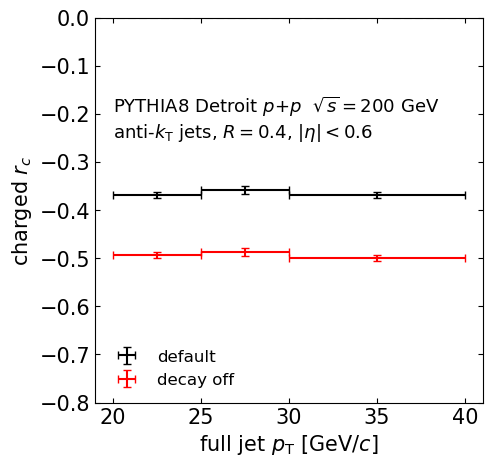

In [27]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_array, xerr=[2.5, 2.5, 5], yerr=rc_err_array, capsize=3, ls='none', label='default', color='k')
plt.errorbar([22.5, 27.5, 35], nodecay_rc_array, xerr=[2.5, 2.5, 5], yerr=nodecay_rc_err_array, capsize=3, ls='none', label='decay off', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.25,'PYTHIA8 Detroit $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$', fontsize=15)
plt.ylim(-0.8,0)
plt.legend(fontsize=12, loc='lower left', frameon=False)
plt.xticks(np.arange(20, 45, 5), fontsize=15)
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

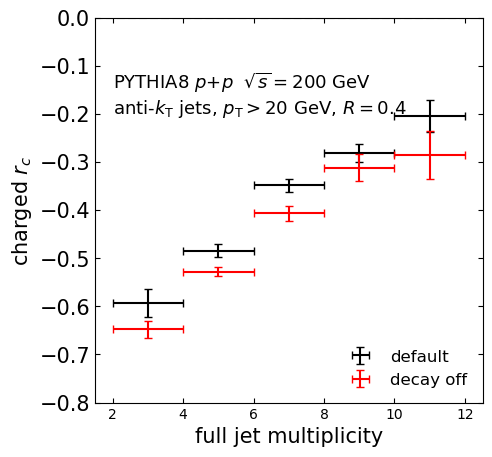

In [23]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(np.arange(3, 13, 2), rc_array, xerr=1, yerr=rc_err_array, capsize=3, ls='none', label='default', color='k')
plt.errorbar(np.arange(3, 13, 2), nodecay_rc_array, xerr=1, yerr=nodecay_rc_err_array, capsize=3, ls='none', label='decay off', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet multiplicity', fontsize=15)
plt.text(2,-0.2,'PYTHIA8 Detroit $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $p_{\mathrm{T}}>20$ GeV, $R=0.4$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$', fontsize=15)
plt.ylim(-0.8,0)
plt.legend(fontsize=12, loc='lower right', frameon=False)
#plt.xticks(np.arange(20, 45, 5), fontsize=15)
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

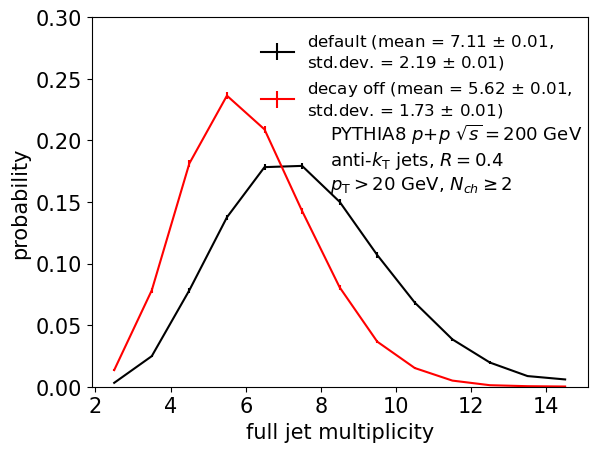

In [48]:
plt.errorbar(np.arange(2.5, 15.5), y, yerr=yerr, color='k', label='default (mean = 7.11 $\pm$ 0.01,\nstd.dev. = 2.19 $\pm$ 0.01)')
plt.errorbar(np.arange(2.5, 15.5), y_nodecay, yerr=yerr_nodecay, color='r', label='decay off (mean = 5.62 $\pm$ 0.01,\nstd.dev. = 1.73 $\pm$ 0.01)')
plt.xlabel(r'full jet multiplicity', fontsize=15)
plt.ylabel('probability', fontsize=15)
plt.text(8.25, 0.16,'PYTHIA8 $p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$\n$p_{\mathrm{T}}>20$ GeV, $N_{ch}\geq2$', fontsize=13)
plt.ylim(0,0.3)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.legend(fontsize=12, loc='upper right', frameon=False)